In [1]:
# import numpy as np
# def sumprod(x,y): 
#     total = 0.
#     for s, g in zip(x,y):
#         total = total + s*g
#     return total
# def deltaG_STP(freeEnergies, stoiciometricCoefficients):
#     assert np.size(stoiciometricCoefficients)==np.size(freeEnergies), "size error"
#     return (sumprod(stoiciometricCoefficients, freeEnergies))

# def prodpower(x,y):  # \prod(x^y)
#     prod = 1.
#     for a, b in zip(x,y):
#         prod = prod + np.pow(a,b)
#     return prod

# constants
F = 96485.33 # [As/mol e-]
RT = 8.3144621*298 # J/mol at 25C
C0 = 273.15 # 0"C to Kelvin



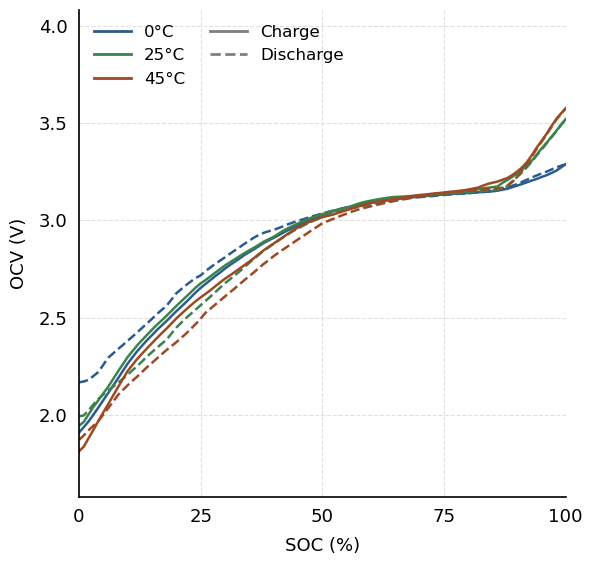

In [2]:
# pull data from csv
import pandas as pd
f17 = pd.read_csv('data/Liu2026_OCV_curve_NFPP_fig17_refined.csv', skipinitialspace=True)
f17.head()

# plot data
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

fig, ax = plt.subplots(figsize=(6, 6))

lines = ['OCV charging 0C', 'OCV discharge 0C', 'OCV charging 25C', 'OCV discharge 25C', 'OCV charging 45C', 'OCV discharge 45C']
colors = ['#2c5c8f', '#3c824d', '#9b4a24']  # @Gemini - exact blue (0°C), green (25°C), and dark orange (45°C) sampled from Fig. 17

for i, line in enumerate(lines):
    color = colors[i // 2]
    linestyle = '--' if 'discharge' in line else '-'  # @Gemini - solid for charging, dashed for discharge
    ax.plot(f17['SOC'], f17[line], color=color, linestyle=linestyle, linewidth=1.8, label=line)

# @Gemini - match the two-column borderless legend from Fig. 17
legend_handles = [
    Line2D([0], [0], color=colors[0], lw=2, linestyle='-', label='0°C'),
    Line2D([0], [0], color=colors[1], lw=2, linestyle='-', label='25°C'),
    Line2D([0], [0], color=colors[2], lw=2, linestyle='-', label='45°C'),
    Line2D([0], [0], color='#7f7f7f', lw=2, linestyle='-', label='Charge'),
    Line2D([0], [0], color='#7f7f7f', lw=2, linestyle='--', label='Discharge'),
]
ax.legend(handles=legend_handles, loc='upper left', ncol=2, frameon=False, fontsize=12, handlelength=2.2, columnspacing=1.5)

# @Gemini - set the aspect ratio to a square to match the original figure
ax.set_box_aspect(1)

ax.set_xlim([0, 100])
ax.set_ylim([1.58, 4.08])
ax.set_xticks([0, 25, 50, 75, 100])
ax.set_yticks([2.0, 2.5, 3.0, 3.5, 4.0])

# Match spine, tick, and dashed grid styling of Fig. 17
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_linewidth(1.2)
ax.spines['bottom'].set_linewidth(1.2)
ax.tick_params(axis='both', which='both', length=0, labelsize=13, pad=8)
ax.grid(True, linestyle='--', color='#e0e0e0', linewidth=0.8)
ax.set_axisbelow(True)

ax.set_xlabel('SOC (%)', fontsize=13, labelpad=8)
ax.set_ylabel('OCV (V)', fontsize=13, labelpad=8)

plt.tight_layout()
plt.show()